# 01 · Exploration des offres d'emploi du service public

**Source** : « Les offres diffusées sur Choisir le service public » (DGAFP, open data, Licence Ouverte), un fichier par année
depuis 2022, consolidé par `offres csp` en une ligne par offre (`csp_offres.parquet` dans la release `donnees`).

Questions de cette étape :
1. Que contient vraiment le fichier, et qu'est-ce qui manque ?
2. Qui recrute, où, à quel niveau, et comment le volume évolue-t-il ?
3. Le télétravail progresse-t-il dans les offres publiques ?
4. Quelle place pour les métiers de la data ?
5. Quels postes sont republiés encore et encore (signe d'un recrutement difficile) ?
6. Le texte « compétences attendues », matière première du NLP de l'étape 4 : combien, où, de quelle qualité ?

In [1]:
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from offres import donnees, familles, graphiques as g, lexique

g.style()
pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(80)

offres = donnees.offres_service_public()
print(f"{offres.height:,} offres, {offres['metier'].n_unique()} métiers, "
      f"du {offres['date_publication'].min()} au {offres['date_publication'].max()}")

1,621,178 offres, 885 métiers, du 2021-01-05 au 2026-09-27


## 1. Ce que contient le fichier

Chaque offre a une référence, un métier (répertoire des métiers de la fonction publique), un intitulé libre, un versant
(État, territoriale, hospitalière), une catégorie (A, B, C), un lieu et une date de première publication. Le reste est très
inégalement rempli.

PosixPath('/home/user/offres-emploi-competences/rapports/figures/01_remplissage.png')

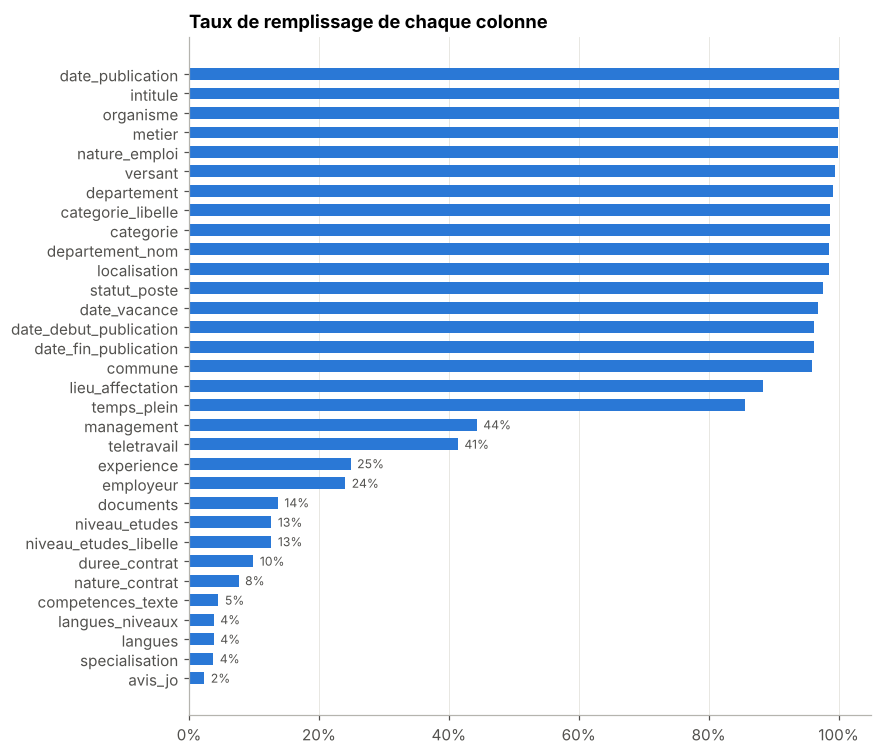

In [2]:
remplissage = (
    offres.select([pl.col(c).is_not_null().mean().alias(c) for c in offres.columns
             if c not in ("fichier_source", "annonce_id", "postes_annonce", "reference")])
    .transpose(include_header=True, header_name="colonne", column_names=["taux"])
    .sort("taux")
)
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(remplissage["colonne"], remplissage["taux"], color=g.PALETTE[0], height=0.6)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Taux de remplissage de chaque colonne")
ax.grid(axis="y", visible=False)
for y, v in enumerate(remplissage["taux"]):
    if v < 0.5:
        ax.text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=8, color="#52514e")
g.enregistrer(fig, "01_remplissage")

Trois colonnes intéressantes pour l'analyse sont rares : le **texte des compétences attendues** (≈ 4,5 % des offres),
le **niveau d'études** et l'**expérience** demandés. Le **télétravail** n'est renseigné que depuis 2023, pour environ une
offre sur deux. Aucun salaire n'est publié : c'est la principale limite de cette source par rapport à France Travail.

## 2. Qui recrute, et quand

versant,len
str,u32
"""Fonction Publique Territoriale""",1004219
"""Fonction Publique de l'Etat""",513321
"""Fonction Publique Hospitalière""",95296


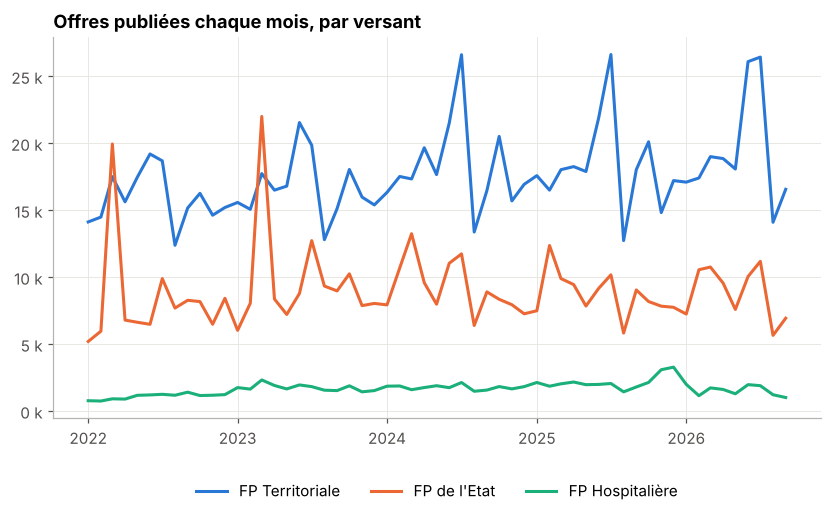

In [3]:
mensuel = (
    offres.filter(pl.col("versant").is_not_null(), pl.col("date_publication") >= pl.date(2022, 1, 1))
    .group_by(pl.col("date_publication").dt.truncate("1mo").alias("mois"), "versant").len()
    .sort("mois")
)
fig, ax = plt.subplots()
for versant, couleur in g.VERSANTS.items():
    s = mensuel.filter(pl.col("versant") == versant)
    ax.plot(s["mois"], s["len"], color=couleur, label=versant.replace("Fonction Publique ", "FP "))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:.0f} k"))
ax.set_title("Offres publiées chaque mois, par versant")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.25), ncols=3)
g.enregistrer(fig, "02_offres_par_mois")
mensuel.group_by("versant").agg(pl.col("len").sum()).sort("len", descending=True)

La territoriale publie près de deux offres sur trois. Son cycle est très régulier : un pic en juin-juillet (les
recrutements pour la rentrée : animation, écoles, cantines) puis une chute en août. L'État a des pics de printemps,
probablement liés aux campagnes annuelles de mobilité des fonctionnaires. Le volume total a crû de 12 % en 2023 puis s'est
stabilisé (353 000 offres en 2024 comme en 2025). Le fichier 2026 s'arrête fin septembre.

In [4]:
par_annee = (
    offres.filter(pl.col("date_publication").dt.year().is_between(2022, 2025))
    .group_by(pl.col("date_publication").dt.year().alias("annee")).len().sort("annee")
)
par_annee.with_columns((pl.col("len") / pl.col("len").shift() - 1).alias("evolution"))

annee,len,evolution
i32,u32,f64
2022,304057,null
2023,339943,0.118024
2024,353621,0.040236
2025,353665,0.000124


versant,A+,A,B,C
str,f64,f64,f64,f64
"""Fonction Publique de l'Etat""",0.050949,0.478033,0.267277,0.203742
"""Fonction Publique Hospitalière""",0.064927,0.455396,0.254696,0.22498
"""Fonction Publique Territoriale""",0.007302,0.232604,0.238355,0.521739


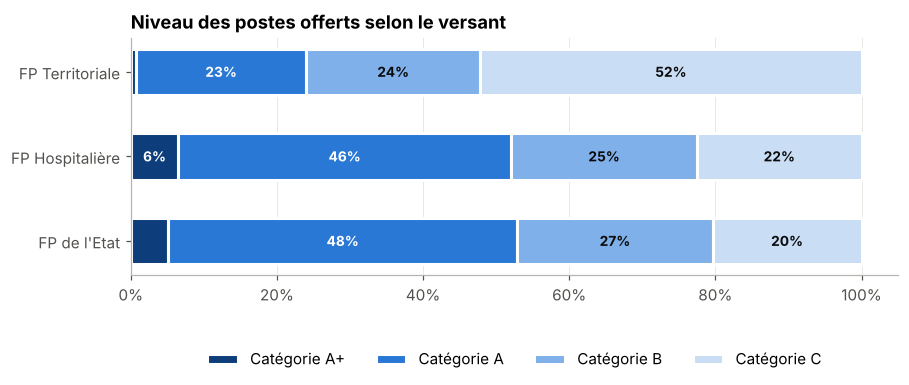

In [5]:
categories = (
    offres.filter(pl.col("versant").is_not_null(), pl.col("categorie").is_not_null())
    .group_by("versant", "categorie").len()
    .with_columns((pl.col("len") / pl.col("len").sum().over("versant")).alias("part"))
    .pivot(on="categorie", index="versant", values="part").fill_null(0)
    .select("versant", "A+", "A", "B", "C")
)
fig, ax = plt.subplots(figsize=(9, 2.8))
gauche = [0.0] * categories.height
noms = [v.replace("Fonction Publique ", "FP ") for v in categories["versant"]]
# Catégories ordonnées : une seule teinte, du plus foncé (A+) au plus clair (C)
teintes = ["#0d3d7a", "#2a78d6", "#7fb0ea", "#c9ddf5"]
for i, cat in enumerate(["A+", "A", "B", "C"]):
    valeurs = categories[cat].to_list()
    ax.barh(noms, valeurs, left=gauche, color=teintes[i], label=f"Catégorie {cat}", height=0.55, edgecolor="white", linewidth=2)
    for y, (x, v) in enumerate(zip(gauche, valeurs)):
        if v > 0.06:
            ax.text(x + v / 2, y, f"{v:.0%}", ha="center", va="center", color="white" if i < 2 else "#0b0b0b",
                    fontsize=9, fontweight="bold")
    gauche = [a + b for a, b in zip(gauche, valeurs)]
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Niveau des postes offerts selon le versant")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.45), ncols=4)
ax.grid(axis="y", visible=False)
g.enregistrer(fig, "03_categories")
categories

L'État et l'hôpital recrutent surtout des cadres (catégories A et A+, plus d'une offre sur deux ; à l'hôpital, les
infirmiers sont en catégorie A), la territoriale surtout des employés (catégorie C, 52 %) : agents techniques, entretien,
animation, restauration scolaire. Comparer les compétences demandées devra donc se faire à niveau égal.

Paris : 7.4% des offres


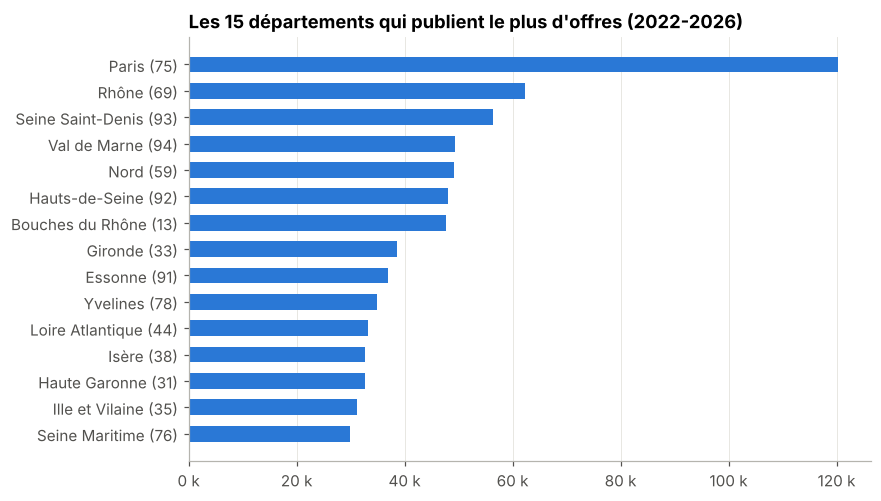

In [6]:
departements = (
    offres.filter(pl.col("departement").is_not_null())
    .group_by("departement", "departement_nom").len().sort("len", descending=True)
)
top = departements.head(15).reverse()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([f"{n} ({d})" for d, n in zip(top["departement"], top["departement_nom"])], top["len"], color=g.PALETTE[0], height=0.6)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:.0f} k"))
ax.set_title("Les 15 départements qui publient le plus d'offres (2022-2026)")
ax.grid(axis="y", visible=False)
g.enregistrer(fig, "04_departements")
print(f"Paris : {departements.row(0, named=True)['len'] / offres.height:.1%} des offres")

Paris concentre 7 % des offres : administrations centrales, AP-HP, Ville de Paris. Le classement suit la population, mais
l'Île-de-France est surreprésentée. La carte par habitant viendra avec le dashboard (étape 7).

## 3. Le télétravail dans les offres publiques

categorie,debut,fin
str,f64,f64
"""A""",0.760679,0.597437
"""B""",0.550535,0.470722
"""C""",0.179662,0.113846


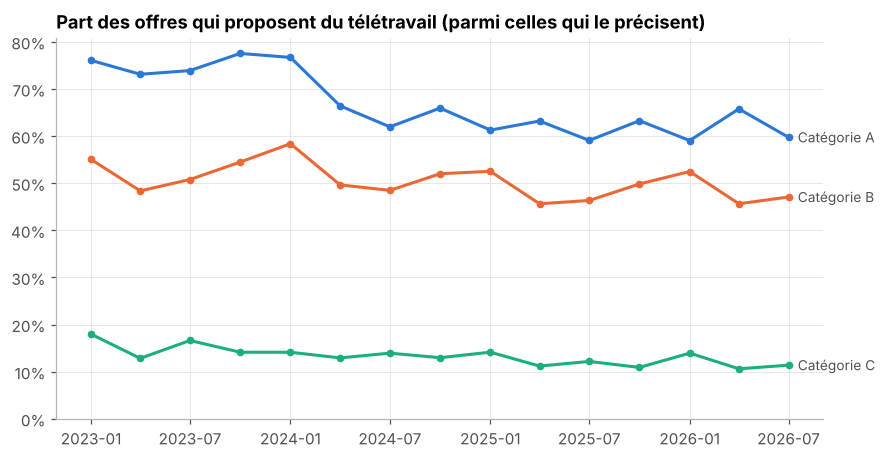

In [7]:
tt = (
    offres.filter(pl.col("teletravail").is_not_null(), pl.col("categorie").is_in(["A", "B", "C"]),
                  pl.col("date_publication").dt.year() >= 2023)
    .group_by(pl.col("date_publication").dt.truncate("1q").alias("trimestre"), "categorie")
    .agg(pl.col("teletravail").mean().alias("part"), pl.len())
    .filter(pl.col("len") >= 500).sort("trimestre")
)
fig, ax = plt.subplots()
for i, cat in enumerate(["A", "B", "C"]):
    s = tt.filter(pl.col("categorie") == cat)
    ax.plot(s["trimestre"], s["part"], color=g.PALETTE[i], marker="o", markersize=4)
    ax.annotate(f"Catégorie {cat}", (s["trimestre"][-1], s["part"][-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color="#52514e")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, None)
ax.set_title("Part des offres qui proposent du télétravail (parmi celles qui le précisent)")
g.enregistrer(fig, "05_teletravail")
tt.group_by("categorie").agg(pl.col("part").first().alias("debut"), pl.col("part").last().alias("fin")).sort("categorie")

Parmi les offres qui précisent ce point, la part proposant du télétravail **recule** depuis 2023, dans les trois
catégories. Le télétravail reste surtout l'affaire des cadres. Prudence : le champ est facultatif et son taux de
remplissage a lui-même changé, donc une partie de l'évolution peut venir de qui le remplit.

## 4. Les métiers de la data dans le service public

In [8]:
data = offres.filter(familles.est_data())
print(f"{data.height:,} offres data ({data.height / offres.height:.2%} du total)")
annuel = (
    offres.filter(pl.col("date_publication").dt.year().is_between(2022, 2026))
    .group_by(pl.col("date_publication").dt.year().alias("annee"))
    .agg(pl.len().alias("toutes"), familles.est_data().sum().alias("data"))
    .with_columns((pl.col("data") / pl.col("toutes") * 10_000).alias("pour_10000"))
    .sort("annee")
)
annuel

11,367 offres data (0.70% du total)


annee,toutes,data,pour_10000
i32,u32,u32,f64
2022,304057,2175,71.53264
2023,339943,2503,73.629991
2024,353621,2567,72.591843
2025,353665,2251,63.647802
2026,269718,1870,69.331672


metier,len,part_A,teletravail,part_paris
str,u32,f64,f64,f64
"""Administratrice / Administratrice de bases de données""",3179,0.525612,0.862903,0.063823
"""Analyste de données""",1423,0.679352,0.900437,0.312772
"""Chargée / Chargé de collecte et d'exploitation de données""",1360,0.220442,0.51234,0.208178
"""Experte / Expert en production, traitement et analyse de données""",992,0.943763,0.852459,0.226708
"""Data Scientist""",910,0.899777,0.78352,0.495475
"""Statisticienne / Statisticien - Chargée / Chargé d'opérations statistiques""",589,0.570447,0.827511,0.194492
"""Data engineer""",559,0.934701,0.939791,0.315217
"""Responsable d'un programme d'études et statistiques""",544,0.804788,0.827309,0.155722
"""Analyste de données RH""",530,0.483871,0.884615,0.462428


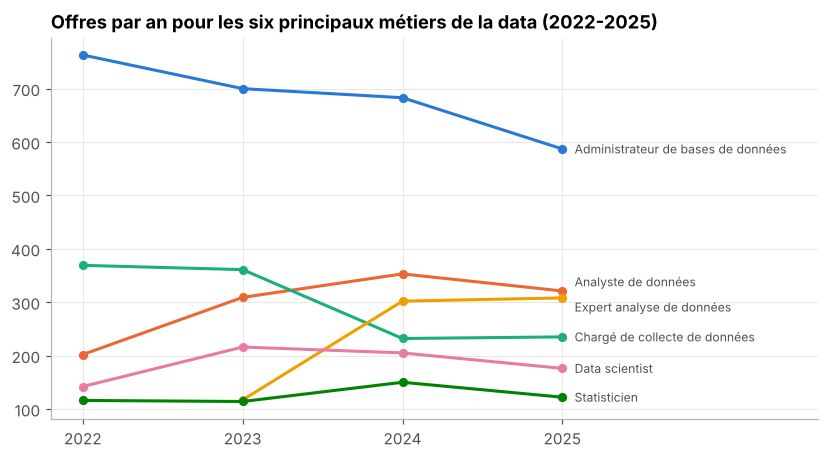

In [9]:
metiers_data = (
    data.filter(pl.col("date_publication").dt.year().is_between(2022, 2025))
    .group_by("metier", pl.col("date_publication").dt.year().alias("annee")).len()
)
courts = {
    "Administratrice / Administratrice de bases de données": ("Administrateur de bases de données", 0),
    "Analyste de données": ("Analyste de données", 6),
    "Experte / Expert en production, traitement et analyse de données": ("Expert analyse de données", -6),
    "Chargée / Chargé de collecte et d'exploitation de données": ("Chargé de collecte de données", 0),
    "Data Scientist": ("Data scientist", 0),
    "Statisticienne / Statisticien - Chargée / Chargé d'opérations statistiques": ("Statisticien", 0),
}
principaux = data.group_by("metier").len().sort("len", descending=True).head(6)["metier"].to_list()
fig, ax = plt.subplots()
for i, m in enumerate(principaux):
    s = metiers_data.filter(pl.col("metier") == m).sort("annee")
    nom, decalage = courts.get(m, (m[:30], 0))
    ax.plot(s["annee"], s["len"], color=g.PALETTE[i], marker="o", markersize=5)
    ax.annotate(nom, (s["annee"][-1], s["len"][-1]), xytext=(8, decalage), textcoords="offset points", va="center",
                fontsize=8, color="#52514e")
ax.set_xticks([2022, 2023, 2024, 2025])
ax.set_xlim(2021.8, 2026.6)
ax.set_title("Offres par an pour les six principaux métiers de la data (2022-2025)")
g.enregistrer(fig, "06_metiers_data")
data.group_by("metier").agg(pl.len(), (pl.col("categorie") == "A").mean().alias("part_A"),
                            pl.col("teletravail").mean().alias("teletravail"),
                            (pl.col("departement") == "75").mean().alias("part_paris")).sort("len", descending=True)

Les métiers de la data restent une niche : 0,7 % des offres, sans progression depuis 2022 (environ 70 offres pour
10 000). Leur profil tranche pourtant avec le reste : majoritairement de catégorie A (90 % pour les data scientists),
télétravail proposé dans 78 à 90 % des offres qui le précisent (contre environ 40 % en moyenne), et une offre de data
scientist sur deux à Paris. Les besoins se déplacent : les administrateurs de bases de données reculent, les analystes et
experts en analyse de données progressent.

## 5. Les postes republiés encore et encore

Une même annonce (même intitulé, même organisme, même commune) publiée à plusieurs dates signale souvent un poste
difficile à pourvoir. On compte les dates de publication distinctes, pour ne pas confondre une republication avec une
annonce multi-postes publiée le même jour (repérée par `postes_annonce`).

4.2% des offres font partie d'une annonce multi-postes
29.5% des offres ont été publiées à au moins deux dates


metier,len,part_3_plus
str,u32,f64
"""Auxiliaire de vie - Aide à domicile""",7132,0.464105
"""Responsable de direction d'un établissement d'éducation""",3202,0.386321
"""Assistante / Assistant d'éducation de la petite enfance""",26982,0.385516
"""Animatrice éducative / Animateur éducatif accompagnement périscolaire""",14011,0.364
"""Animatrice / Animateur enfance-jeunesse""",32357,0.34654
"""Animatrice / Animateur de relais assistantes maternelles""",28525,0.290727
"""Agente locale / Agent local de tranquillité publique""",22591,0.284715
"""Aide-soignante / Aide-soignant""",17825,0.278093
"""Chargée / Chargé de propreté des espaces publics""",14989,0.271866


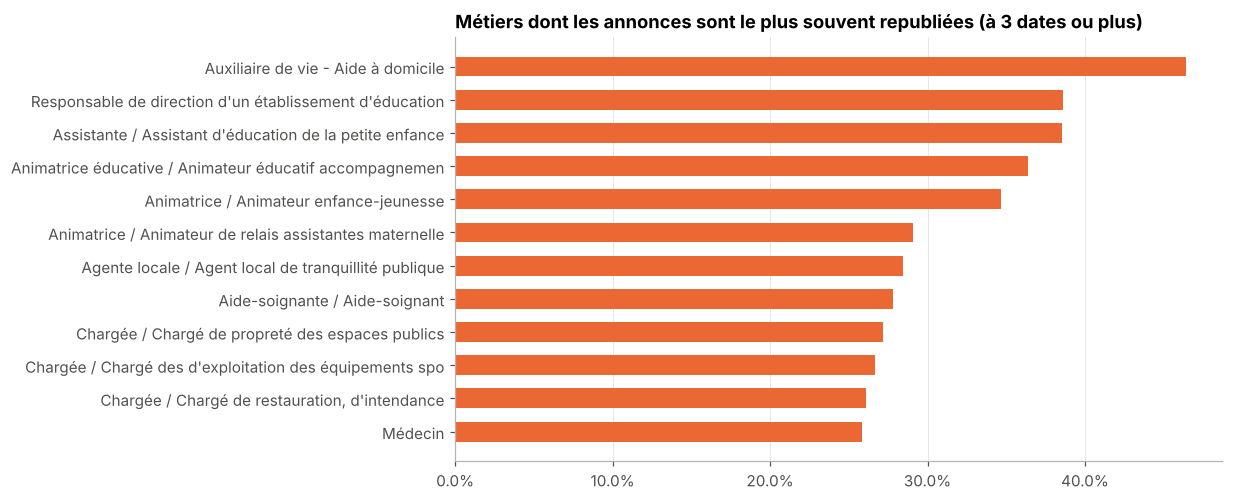

In [10]:
annonces = offres.with_columns(pl.col("date_publication").n_unique().over("intitule", "organisme", "commune").alias("publications"))
print(f"{(annonces['postes_annonce'] > 1).mean():.1%} des offres font partie d'une annonce multi-postes")
print(f"{(annonces['publications'] > 1).mean():.1%} des offres ont été publiées à au moins deux dates")
republi = (
    annonces.group_by("metier")
    .agg(pl.len(), (pl.col("publications") >= 3).mean().alias("part_3_plus"))
    .filter(pl.col("len") >= 3000).sort("part_3_plus", descending=True)
)
top = republi.head(12).reverse()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([m[:55] for m in top["metier"]], top["part_3_plus"], color=g.PALETTE[1], height=0.6)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Métiers dont les annonces sont le plus souvent republiées (à 3 dates ou plus)")
ax.grid(axis="y", visible=False)
g.enregistrer(fig, "07_republications")
republi.head(12)

L'aide à domicile, la petite enfance et l'animation périscolaire dominent, suivies des agents de tranquillité publique,
des aides-soignants et, plus haut dans la hiérarchie, des directions d'établissements scolaires et des médecins. Ce sont
pour l'essentiel des métiers peu qualifiés, souvent à temps partiel, que les collectivités peinent à pourvoir.
Ce signal servira de cible de repli pour la modélisation (étape 6), faute de salaire.

## 6. Le texte des compétences attendues

In [11]:
textes = offres.filter(pl.col("competences_texte").is_not_null())
print(f"{textes.height:,} textes, longueur médiane {textes['competences_texte'].str.len_chars().median():.0f} caractères")
textes.group_by("versant").len().sort("len", descending=True)

73,359 textes, longueur médiane 358 caractères


versant,len
str,u32
"""Fonction Publique de l'Etat""",64293
"""Fonction Publique Hospitalière""",8826
"""Fonction Publique Territoriale""",232
null,8


In [12]:
for t in textes.filter(familles.est_data()).sample(2, seed=1)["competences_texte"]:
    print(t[:700], "\n" + "-" * 80)

Savoirs généraux, théoriques ou disciplinaires : 
-	Instrumentation de robot manufacturier 
-	Traitement d'images de caméras
-	Analyse et exploitation des données
-	Intelligence Artificielle et apprentissages profonds

Savoir-faire opérationnels : 
-	Programmation Python
-	Compétences en Sciences des Données et I.A.
-	Rédaction d'article scientifique

Savoir-être : 
-	Bon relationnel
-	Rigueur
-	Implication 
--------------------------------------------------------------------------------
- DEMARCHE PROCESSUS
- INFORMATIQUE DECISIONNELLE
- ORGANISATION ET METHODE
- AIDE A LA DECISION ALD
- ARCHITECTURES ET TECHNIQUES BIG DATA
- CONCEPTION ET MISE EN OEUVRE DES CONTENUS DIGITAUX
- CONNAISSANCE DES PRINCIPES ET REGLES NECESSAIRES A LA BONNE EXECUTION FINANCIERE DES MARCHES PUBLICS
- REGLES DE REALISATION D'UNE OPERATION D'INFRA 
--------------------------------------------------------------------------------


c,len
str,u32
"""Bureautique (générique)""",15175
"""Pack Office""",4260
"""Excel""",4067
"""Anglais""",3997
"""Cybersécurité""",1526
"""Réseaux""",830
"""Linux""",578
"""Python""",536
"""Statistiques""",491


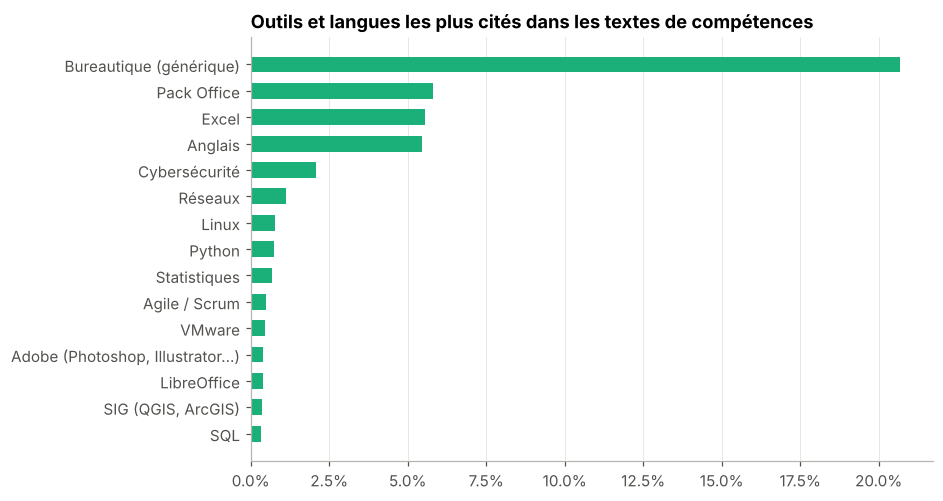

In [13]:
outils = (
    textes.select(pl.col("competences_texte").map_elements(lexique.extraire, return_dtype=pl.List(pl.Utf8)).alias("c"))
    .explode("c").drop_nulls().group_by("c").len().sort("len", descending=True)
)
top = outils.head(15).reverse()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["c"], top["len"] / textes.height, color=g.PALETTE[2], height=0.6)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Outils et langues les plus cités dans les textes de compétences")
ax.grid(axis="y", visible=False)
g.enregistrer(fig, "08_outils_cites")
outils.head(15)

Les textes existent surtout pour la fonction publique de l'État et décrivent des savoir-faire et savoir-être bien plus
que des outils : le lexique d'outils n'y trouve presque que la bureautique, l'anglais et quelques langages. L'étape 4
devra donc s'appuyer sur le **référentiel ROME** (20 000 savoir-faire, 15 700 savoirs) plutôt que sur un lexique d'outils,
et rapprocher aussi chaque **métier** de sa fiche ROME pour estimer les compétences demandées sur les 1,6 million d'offres,
pas seulement sur les 4,5 % qui ont un texte.

## À retenir

- 1,6 million d'offres uniques de 2022 à septembre 2026, deux sur trois dans la territoriale ; pas de salaire.
- L'État et l'hôpital recrutent surtout des cadres, la territoriale surtout des employés : toute comparaison se fait à
  catégorie égale.
- Le télétravail proposé recule depuis 2023 (parmi les offres qui le précisent).
- La data pèse 0,7 % des offres, sans progression, mais ce sont surtout des postes de cadres, télétravaillables.
- Les annonces les plus republiées sont celles de l'aide à domicile, de l'animation et de la petite enfance :
  un indicateur de tension utilisable faute de salaire.
- Le texte de compétences ne couvre que 4,5 % des offres, surtout à l'État : le NLP passera par le référentiel ROME.